State powers from Basic PB Calculator: {'No Control': 0.54, 'Detumble': 5.01, 'Sun-Pointing': 5.2, 'Pointing Away': 5.2, 'RF Pass': 5.98, 'Payload - Calibration': 14.59, 'Payload - Acquisition': 23.55, 'Safe Mode': 0.64}
Running case: PULSEPowerMinE   (PULSEPowerMinE.csv)
Saved summary to: C:\Users\Jeongwon Lee\UCSP\new_new_new_PULSE_A_PB_calc\sim_outputs\PULSEPowerMinE_orbit_summary.csv
Minimum SoC: 87.20 %   Maximum SoC: 95.00 %   Final SoC: 93.48 %
Max timing mismatch (duration - eclipse - sunlight): 2.842170943040401e-14


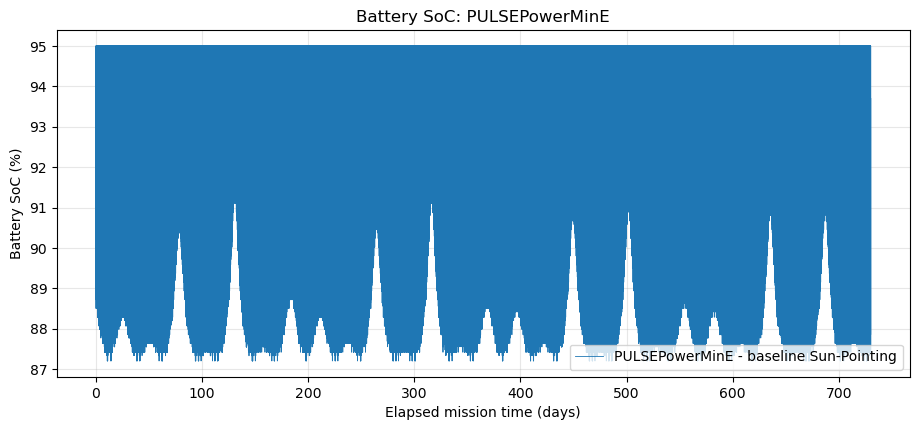

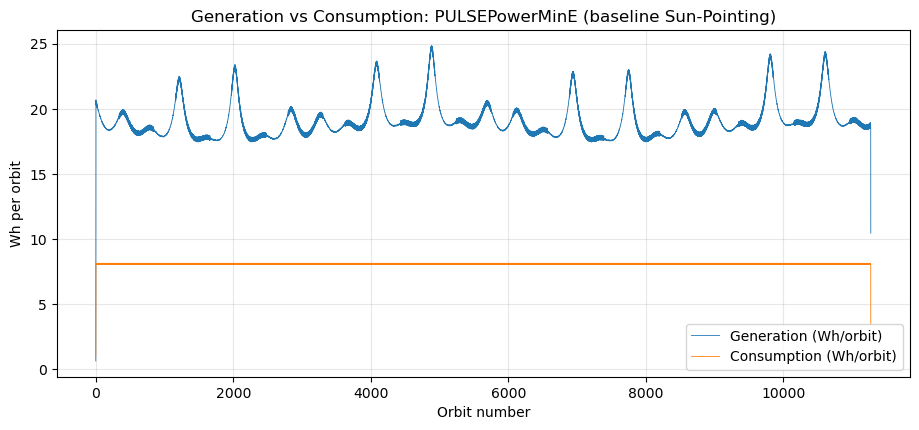

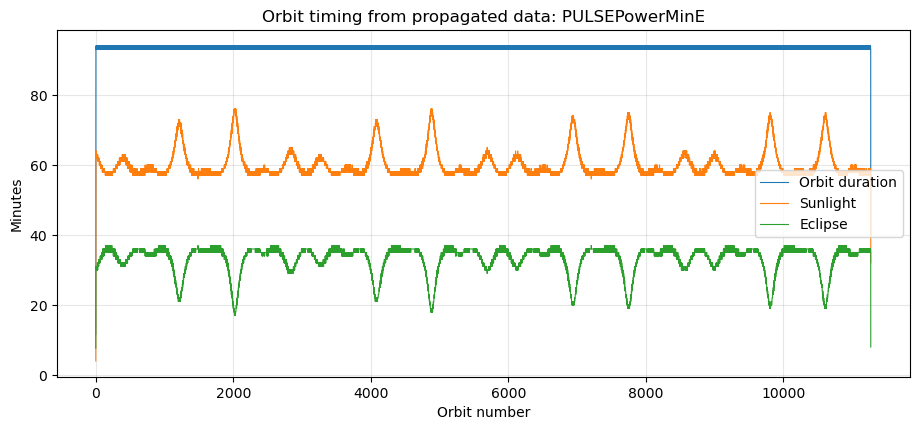

Running case: PULSEPowerMaxE   (PULSEPowerMaxE.csv)
Saved summary to: C:\Users\Jeongwon Lee\UCSP\new_new_new_PULSE_A_PB_calc\sim_outputs\PULSEPowerMaxE_orbit_summary.csv
Minimum SoC: 87.20 %   Maximum SoC: 95.00 %   Final SoC: 90.23 %
Max timing mismatch (duration - eclipse - sunlight): 1.4210854715202004e-14


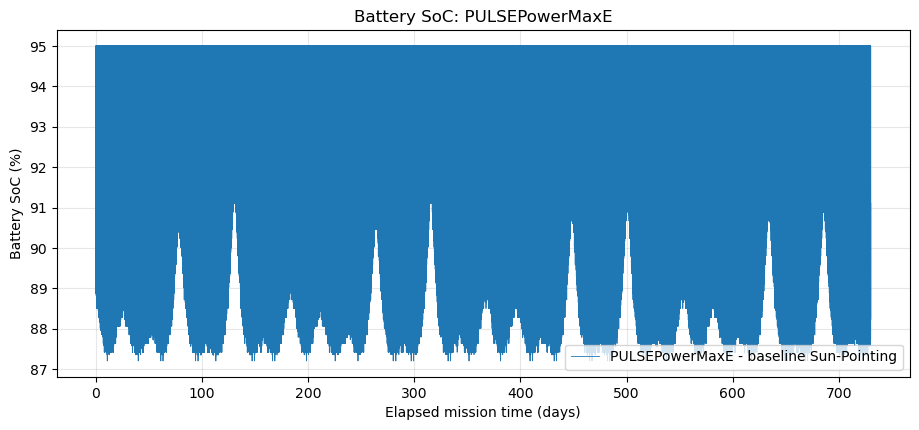

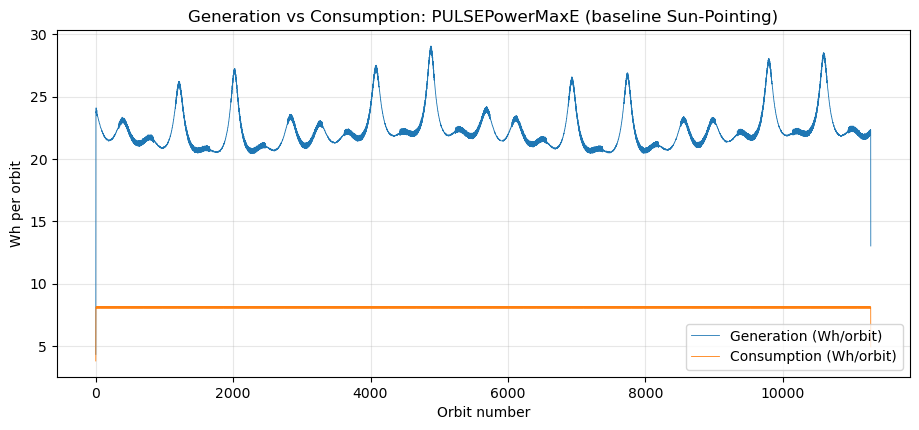

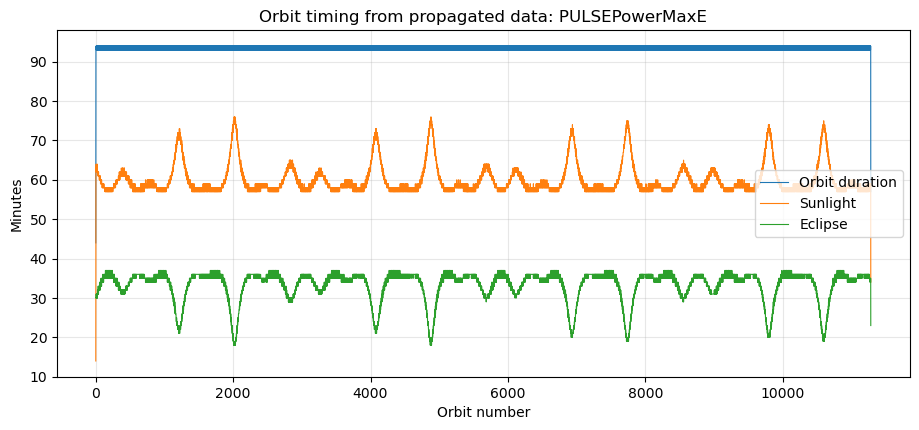

In [2]:
"""
new_mission_power_simulation.py
===============================

Shared engine for the PULSE-A timestep power / battery simulation.

This file is the importable version of ``new_mission_power_simulation.ipynb``.
The functions keep the same names and the same math as the notebook so the
notebook, ``new_analyze.ipynb``, ``new_viz (1).ipynb`` and ``fixviz (2).ipynb``
all run on ONE engine:

    0. path setup               -> find_data_file(), find_power_budget_file()
    1. power-budget model       -> load_power_budget_calculator(), get_state_powers()
    2. read source data         -> read_csv_power_file()      (STK reader + column map)
    3. time columns             -> add_time_columns()
    4. generation               -> detect_profile_type(), add_generation_column()
    5. spacecraft state         -> choose_spacecraft_state(), OpsSchedule
    6. battery simulation       -> run_csv_mission_simulation()
    7. per-orbit summary        -> summarize_by_orbit(), orbit_flags()
    8. save                     -> save_orbit_summary()
    9. plots                    -> plot_soc(), plot_generation_vs_consumption(), plot_orbit_timing()
   10. validation               -> validate_profile(), print_validation_report()
   11. orbit geometry helpers   -> estimate_orbit_from_profile(), min_inclination_for_station(),
                                   propagate_eclipse_profile()   (first-order, for the
                                   orbit-requirements questions: altitude / inclination /
                                   eccentricity envelope)

Core equations (unchanged from the notebook)
--------------------------------------------
    t_hours       = 24 * t_days
    dt_i          = t_(i+1) - t_i                       (real STK timestep, not 1 min assumed)
    E_gen,i       = E_cum,i - E_cum,i-1                 (cumulative column)   or
    E_gen,i       = P_i * dt_i                          (instantaneous column)
    E_cons,i      = P_state,i * dt_i
    SOC_i         = clip(SOC_(i-1) + E_gen,i - E_cons,i, 0, SOC_max)
    T_orbit       = sum(dt_i in orbit)
    T_eclipse     = sum(dt_i where InShadow == 1)
    T_sunlight    = sum(dt_i where InShadow == 0)
    check:  T_orbit == T_eclipse + T_sunlight
"""

from __future__ import annotations

import importlib.util
import os
import sys
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. PATH SETUP
# ==========================================

root = Path.cwd()

# Folders that are searched (in this order) for data / power-budget files.
# The notebooks live in "PULSE-A Timestep Sim/", one level below the project
# folder, so both this folder and its parent are searched.
SEARCH_DIRS = []
for _base in (root, root.parent):
    SEARCH_DIRS += [
        _base,
        _base / "CSV Data",
        _base / "data",
        _base / "_ORGANIZED" / "1_IMPORTANT" / "data" / "stk_power_v2_download_from_drive",
        _base / "_ORGANIZED" / "1_IMPORTANT" / "code",
    ]

OUTPUT_DIR = root / "sim_outputs"

# Battery / limits (single place to change them).
# NOTE: the PPRR deck lists the flight pack as 2P2S Samsung 35E = 50.4 Wh,
# usable 10.7 %-92.9 % SoC.  40 Wh is kept as the conservative default so
# results stay comparable with earlier runs; 50.4 Wh is run as a sensitivity case.
BATTERY_CAPACITY_WH = 40.0
INITIAL_SOC_FRACTION = 0.95
MAX_SOC_FRACTION = 0.95
RECOVERY_SOC_FRACTION = 0.33   # DoD / recovery threshold
WARNING_SOC_FRACTION = 0.20    # operational warning
SAFE_MODE_SOC_FRACTION = 0.15  # ConOps: enter safe mode below 15 %
SAFE_EXIT_SOC_FRACTION = 0.50  # ConOps: exit safe mode above 50 %
HARD_FLOOR_SOC_FRACTION = 0.10


def find_data_file(stem, extensions=(".csv", ".xls", ".txt")):
    """
    Find a data file by name stem, e.g. "PULSEPowerMinE".

    Also accepts browser-download copies such as "PULSEPowerMinE (1).csv".
    """
    for folder in SEARCH_DIRS:
        for ext in extensions:
            for name in (f"{stem}{ext}", f"{stem} (1){ext}", f"{stem} (2){ext}"):
                candidate = folder / name
                if candidate.is_file() and candidate.stat().st_size > 1000:
                    return candidate
    raise FileNotFoundError(
        f"Could not find {stem!r}. Put it next to the notebook or in one of: "
        + ", ".join(str(d) for d in SEARCH_DIRS)
    )


def find_power_budget_file():
    """Locate 'Basic PB Calculator.py' (the separate power-budget model)."""
    for folder in SEARCH_DIRS:
        candidate = folder / "Basic PB Calculator.py"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("Could not find 'Basic PB Calculator.py'")


# Simulation cases. Change only this dict to add D2S2 / FreeFlyer / new STK runs.
csv_cases = {
    "PULSEPowerMinE": {"stem": "PULSEPowerMinE", "generation_column": "MinTotalPower"},
    "PULSEPowerMaxE": {"stem": "PULSEPowerMaxE", "generation_column": "MaxTotalPower"},
}


# ==========================================
# 1. LOAD BASIC PB CALCULATOR
# ==========================================

def load_power_budget_calculator(power_budget_file=None):
    """
    Import PowerBudgetCalculator from 'Basic PB Calculator.py'.
    The import is done with importlib because the filename contains spaces.
    """
    power_budget_file = Path(power_budget_file or find_power_budget_file())
    spec = importlib.util.spec_from_file_location("basic_pb", power_budget_file)
    module = importlib.util.module_from_spec(spec)

    old_stdout = sys.stdout
    try:
        sys.stdout = open(os.devnull, "w")  # hide prints that run on import
        spec.loader.exec_module(module)
    finally:
        sys.stdout.close()
        sys.stdout = old_stdout
    return module.PowerBudgetCalculator


STATE_NAMES = [
    "No Control",
    "Detumble",
    "Sun-Pointing",
    "Pointing Away",
    "RF Pass",
    "Payload - Calibration",
    "Payload - Acquisition",
]


def get_state_powers(power_budget_file=None):
    """
    Spacecraft power draw per state [W] from Basic PB Calculator.py.

    "Safe Mode" is not defined in the PB calculator yet, so it is mapped to the
    "No Control" base load (PMCU, watchdog, current sensors, 5 % heater) plus
    radio RX, i.e. "pause non-essential systems for minimum power draw".
    Update this once EPS defines the safe-mode load list.
    """
    calc = load_power_budget_calculator(power_budget_file)()
    state_powers = {name: calc.calculate_watts(name) for name in STATE_NAMES}
    state_powers["Safe Mode"] = round(state_powers["No Control"] + 0.10, 2)
    return state_powers


# ==========================================
# 2. READ SOURCE SIMULATION DATA
# ==========================================

# Column mapping: tool column name -> standard name used by the engine.
# To use D2S2 / FreeFlyer output, add a map with that tool's column names.
STK_COLUMN_MAP = {
    "PULSE.ElapsedTime": "elapsed_days",
    "PULSE.InShadow": "in_shadow",
    "PULSE.OrbitNumberBounded": "orbit_number",
    "MaxTotalPower": "MaxTotalPower",
    "MinTotalPower": "MinTotalPower",
}

# Unit of the elapsed-time column -> factor to convert to days.
TIME_UNIT_TO_DAYS = {"day": 1.0, "days": 1.0, "hr": 1 / 24, "hour": 1 / 24, "min": 1 / 1440, "sec": 1 / 86400, "s": 1 / 86400}


def read_csv_power_file(filepath, column_map=None):
    """
    Read an STK PULSEPower file (whitespace-separated, despite the .csv name).

    Layout: blank line, header row, units row, numeric rows.
    The header row is read so columns are found BY NAME, not by position.
    """
    column_map = column_map or STK_COLUMN_MAP
    filepath = Path(filepath)

    with open(filepath, "r") as f:
        lines = [line for line in (next(f) for _ in range(6)) if line.strip()]
    headers = lines[0].split()
    units = lines[1].split()
    skip = 0
    with open(filepath, "r") as f:
        for line in f:
            skip += 1
            if line.strip() and line.split() == units:
                break

    data = np.loadtxt(filepath, skiprows=skip)

    csv_data = {"source_file": str(filepath), "headers": headers, "units": units}
    for col_index, name in enumerate(headers):
        std_name = column_map.get(name, name)
        csv_data[std_name] = data[:, col_index]

    # Convert time unit to days if needed.
    time_unit = units[headers.index(next(k for k, v in column_map.items() if v == "elapsed_days"))].lower()
    csv_data["elapsed_days"] = csv_data["elapsed_days"] * TIME_UNIT_TO_DAYS.get(time_unit, 1.0)

    csv_data["in_shadow_raw"] = csv_data["in_shadow"].copy()
    csv_data["in_shadow"] = np.rint(csv_data["in_shadow"]).astype(int)
    csv_data["orbit_number"] = np.rint(csv_data["orbit_number"]).astype(int)
    return csv_data


# ==========================================
# 3. COMPUTE REAL TIMING
# ==========================================

def add_time_columns(csv_data):
    """Convert elapsed days to hours/minutes and compute the real timestep width."""
    elapsed_days = csv_data["elapsed_days"]
    elapsed_hours = elapsed_days * 24.0
    elapsed_minutes = elapsed_days * 24.0 * 60.0

    dt_hours = np.zeros(len(elapsed_hours))
    dt_hours[:-1] = elapsed_hours[1:] - elapsed_hours[:-1]
    dt_hours[-1] = dt_hours[-2]  # last row: repeat previous width

    csv_data["elapsed_hours"] = elapsed_hours
    csv_data["elapsed_minutes"] = elapsed_minutes
    csv_data["dt_hours"] = dt_hours
    csv_data["dt_minutes"] = dt_hours * 60.0
    return csv_data


# ==========================================
# 4. COMPUTE GENERATION
# ==========================================

def detect_profile_type(values, monotonic_threshold=0.995):
    """
    'cumulative' if the column almost never decreases (energy-like, Wh),
    otherwise 'instantaneous' (power, W).  Same heuristic as Basic PB Calculator.
    """
    diffs = np.diff(values)
    ratio = np.mean(diffs >= 0) if len(diffs) else 0.0
    return "cumulative" if ratio > monotonic_threshold else "instantaneous"


def add_generation_column(csv_data, generation_column, profile_type="auto", noise_tol_wh=1e-6):
    """
    Per-timestep generated energy [Wh].

    cumulative:     E_gen,i = E_cum,i - E_cum,i-1
    instantaneous:  E_gen,i = P_i * dt_i
    Negative steps are clipped to 0 and COUNTED so they can be reported
    (tiny ones are numerical noise; large ones would mean a reset / unit issue).
    """
    values = csv_data[generation_column]
    if profile_type == "auto":
        profile_type = detect_profile_type(values)

    if profile_type == "cumulative":
        generation_wh = np.zeros(len(values))
        generation_wh[1:] = values[1:] - values[:-1]
    else:
        generation_wh = values * csv_data["dt_hours"]

    negative = generation_wh < 0
    csv_data["negative_generation_steps"] = int(negative.sum())
    csv_data["negative_generation_large"] = int((generation_wh < -noise_tol_wh).sum())
    csv_data["generation_wh"] = np.clip(generation_wh, 0.0, None)
    csv_data["generation_w"] = csv_data["generation_wh"] / np.where(csv_data["dt_hours"] > 0, csv_data["dt_hours"], np.nan)
    csv_data["profile_type"] = profile_type
    csv_data["generation_column"] = generation_column
    return csv_data


def load_case(case_name=None, filepath=None, generation_column=None):
    """Read + time columns + generation in one call."""
    if filepath is None:
        info = csv_cases[case_name]
        filepath = find_data_file(info["stem"])
        generation_column = generation_column or info["generation_column"]
    csv_data = read_csv_power_file(filepath)
    csv_data = add_time_columns(csv_data)
    csv_data = add_generation_column(csv_data, generation_column)
    csv_data["case_name"] = case_name or Path(filepath).stem
    return csv_data


def add_orbit_clock(csv_data):
    """
    Minutes since the start of the current orbit, and minutes since the start
    of the current eclipse / sunlight segment.  Used by the operations schedule.
    """
    orbit = csv_data["orbit_number"]
    shadow = csv_data["in_shadow"]
    t = csv_data["elapsed_minutes"]

    orbit_start_idx = np.r_[0, np.where(np.diff(orbit) != 0)[0] + 1]
    orbit_start_t = np.repeat(t[orbit_start_idx], np.diff(np.r_[orbit_start_idx, len(t)]))
    csv_data["minute_in_orbit"] = t - orbit_start_t

    seg_start_idx = np.r_[0, np.where(np.diff(shadow) != 0)[0] + 1]
    seg_start_t = np.repeat(t[seg_start_idx], np.diff(np.r_[seg_start_idx, len(t)]))
    csv_data["minute_in_segment"] = t - seg_start_t
    # Count of eclipses entered so far (one per orbit) -> used as a "day/orbit counter"
    csv_data["elapsed_day_index"] = np.floor(csv_data["elapsed_days"]).astype(int)
    return csv_data


# ==========================================
# 5. CHOOSE SPACECRAFT STATE
# ==========================================

@dataclass
class OpsSchedule:
    """
    Simple, editable mission-operations schedule.

    Defaults are a *realistic* first cut taken from project data:
      - RF passes: access study (500 km, 42 deg) ~ 517 RF passes / 3 months
        ~ 5.7 per day -> modelled as one 10-min RF Pass every 3rd orbit.
      - Payload acquisition: optical passes happen at night (OGS checklist:
        weather + night), so it is scheduled in ECLIPSE, 10 min, once per day.
      - Payload calibration: once per day, 10 min, in sunlight (분석.docx suggestion).
      - Detumble: first `detumble_hours` after deployment.
      - Safe mode: SoC < 15 % -> Safe Mode until SoC > 50 % (ConOps logic).
    """
    detumble_hours: float = 6.0
    rf_every_n_orbits: int = 3
    rf_minutes: float = 10.0
    payload_every_n_days: int = 1
    payload_minutes: float = 10.0
    calib_every_n_days: int = 1
    calib_minutes: float = 10.0
    use_safe_mode: bool = True
    name: str = "realistic ops"


BASELINE = None  # no schedule -> Sun-Pointing everywhere (notebook baseline)

HEAVY_OPS = OpsSchedule(
    rf_every_n_orbits=1, rf_minutes=10.0,
    payload_every_n_days=1, payload_minutes=10.0,
    calib_every_n_days=1, calib_minutes=10.0,
    name="heavy ops (RF every orbit + daily payload/calibration)",
)

PAYLOAD_EVERY_ORBIT = OpsSchedule(
    rf_every_n_orbits=1, rf_minutes=10.0,
    payload_every_n_days=0, payload_minutes=10.0,   # 0 -> every orbit (stress case)
    calib_every_n_days=0, calib_minutes=10.0,
    name="stress: payload + calibration + RF every orbit",
)


def choose_spacecraft_state(
    orbit_number,
    in_shadow,
    minute_in_orbit,
    minute_in_segment=0.0,
    elapsed_hours=0.0,
    first_orbit_of_day=False,
    schedule=None,
    in_safe_mode=False,
):
    """
    Decide the spacecraft operating state at one timestep.

    schedule=None  -> baseline: Sun-Pointing in eclipse and sunlight
                      (identical to new_mission_power_simulation.ipynb).
    schedule=OpsSchedule(...) -> RF / payload / calibration / detumble / safe mode.
    Priority: Safe Mode > Detumble > Payload Acquisition > Calibration > RF Pass > Sun-Pointing
    """
    if schedule is None:
        return "Sun-Pointing"

    if in_safe_mode:
        return "Safe Mode"

    if elapsed_hours < schedule.detumble_hours:
        return "Detumble"

    payload_orbit = (schedule.payload_every_n_days == 0) or first_orbit_of_day
    if in_shadow == 1 and payload_orbit and minute_in_segment < schedule.payload_minutes:
        return "Payload - Acquisition"

    calib_orbit = (schedule.calib_every_n_days == 0) or first_orbit_of_day
    if in_shadow == 0 and calib_orbit and minute_in_segment < schedule.calib_minutes:
        return "Payload - Calibration"

    if schedule.rf_every_n_orbits > 0 and orbit_number % schedule.rf_every_n_orbits == 0:
        # place the RF window in the middle of the orbit
        if 40.0 <= minute_in_orbit < 40.0 + schedule.rf_minutes:
            return "RF Pass"

    return "Sun-Pointing"


# ==========================================
# 6. RUN CSV-DRIVEN BATTERY SIMULATION
# ==========================================

def run_csv_mission_simulation(
    case_name,
    filepath=None,
    generation_column=None,
    battery_capacity_wh=BATTERY_CAPACITY_WH,
    initial_soc_fraction=INITIAL_SOC_FRACTION,
    max_soc_fraction=MAX_SOC_FRACTION,
    schedule=None,
    constant_load_w=None,
    csv_data=None,
    state_powers=None,
    start_index=0,
):
    """
    Battery simulation directly from the propagated data.

    No fixed 90-min orbit, no fixed 55/35 sunlight/eclipse split:
    real timestamps, real shadow flag and real orbit numbers are used.

    constant_load_w : if given, overrides the state logic with a flat load
                      (e.g. 9.10 W = 13.65 Wh per 90-min orbit, master budget).
    start_index     : start the mission part-way through the profile
                      (used to test different insertion dates / seasons).
    """
    state_powers = state_powers or get_state_powers()
    if csv_data is None:
        csv_data = load_case(case_name, filepath, generation_column)
    if "minute_in_orbit" not in csv_data:
        csv_data = add_orbit_clock(csv_data)

    sl = slice(start_index, None)
    orbit_number = csv_data["orbit_number"][sl]
    in_shadow = csv_data["in_shadow"][sl]
    dt_hours = csv_data["dt_hours"][sl]
    generation_wh = csv_data["generation_wh"][sl]
    minute_in_orbit = csv_data["minute_in_orbit"][sl]
    minute_in_segment = csv_data["minute_in_segment"][sl]
    elapsed_hours = csv_data["elapsed_hours"][sl] - csv_data["elapsed_hours"][start_index]
    day_index = np.floor(elapsed_hours / 24.0).astype(int)

    # first orbit of each mission day (for once-per-day activities)
    orbit_first_day = {}
    for orb, day in zip(orbit_number[np.r_[0, np.where(np.diff(orbit_number) != 0)[0] + 1]],
                        day_index[np.r_[0, np.where(np.diff(orbit_number) != 0)[0] + 1]]):
        orbit_first_day.setdefault(day, orb)
    first_orbits = set(orbit_first_day.values())

    n = len(orbit_number)
    soc_wh = np.zeros(n)
    consumption_wh = np.zeros(n)
    power_draw_w = np.zeros(n)
    state_history = np.empty(n, dtype=object)

    soc = battery_capacity_wh * initial_soc_fraction
    max_soc = battery_capacity_wh * max_soc_fraction
    clipped_wh = 0.0       # energy thrown away at the charge cap (-> could be Pointing Away)
    safe = False
    safe_entries = 0

    for i in range(n):
        if constant_load_w is not None:
            state_name = "Constant load"
            p = constant_load_w
        else:
            if schedule is not None and schedule.use_safe_mode:
                frac = soc / battery_capacity_wh
                if not safe and frac < SAFE_MODE_SOC_FRACTION:
                    safe, safe_entries = True, safe_entries + 1
                elif safe and frac > SAFE_EXIT_SOC_FRACTION:
                    safe = False
            state_name = choose_spacecraft_state(
                orbit_number=orbit_number[i],
                in_shadow=in_shadow[i],
                minute_in_orbit=minute_in_orbit[i],
                minute_in_segment=minute_in_segment[i],
                elapsed_hours=elapsed_hours[i],
                first_orbit_of_day=orbit_number[i] in first_orbits,
                schedule=schedule,
                in_safe_mode=safe,
            )
            p = state_powers[state_name]

        state_history[i] = state_name
        power_draw_w[i] = p
        consumption_wh[i] = p * dt_hours[i]

        soc = soc + generation_wh[i] - consumption_wh[i]
        if soc > max_soc:
            clipped_wh += soc - max_soc
            soc = max_soc
        if soc < 0.0:
            soc = 0.0
        soc_wh[i] = soc

    results = {
        "case_name": case_name,
        "schedule_name": "constant %.2f W" % constant_load_w if constant_load_w is not None
                         else (schedule.name if schedule is not None else "baseline Sun-Pointing"),
        "battery_capacity_wh": battery_capacity_wh,
        "elapsed_days": csv_data["elapsed_days"][sl],
        "elapsed_hours": csv_data["elapsed_hours"][sl],
        "elapsed_minutes": csv_data["elapsed_minutes"][sl],
        "dt_hours": dt_hours,
        "dt_minutes": dt_hours * 60.0,
        "orbit_number": orbit_number,
        "in_shadow": in_shadow,
        "generation_wh": generation_wh,
        "consumption_wh": consumption_wh,
        "power_draw_w": power_draw_w,
        "soc_wh": soc_wh,
        "soc_percent": 100.0 * soc_wh / battery_capacity_wh,
        "state_history": state_history,
        "clipped_wh": clipped_wh,
        "safe_mode_entries": safe_entries,
    }
    return results


# ==========================================
# 7. PER-ORBIT SUMMARY
# ==========================================

SUMMARY_COLUMNS = [
    "orbit", "orbit_duration_min", "eclipse_min", "sunlight_min",
    "generation_wh", "consumption_wh", "min_power_w", "max_power_w",
    "mean_power_w", "min_soc_percent", "max_soc_percent", "final_soc_percent",
]
COL = {name: k for k, name in enumerate(SUMMARY_COLUMNS)}


def summarize_by_orbit(results):
    """
    Per-orbit summary table (same 12 columns as the notebook).

    Uses np.add.reduceat on contiguous orbit blocks, which gives the same
    numbers as the notebook's np.where loop but ~100x faster on 1M rows.
    Orbit duration = SUM of timestep widths (avoids the off-by-one error of
    last timestamp - first timestamp).
    """
    orbit = results["orbit_number"]
    starts = np.r_[0, np.where(np.diff(orbit) != 0)[0] + 1]
    ends = np.r_[starts[1:], len(orbit)] - 1

    dt = results["dt_minutes"]
    shadow = results["in_shadow"]
    p = results["power_draw_w"]
    soc = results["soc_percent"]

    duration = np.add.reduceat(dt, starts)
    eclipse = np.add.reduceat(dt * (shadow == 1), starts)
    sunlight = np.add.reduceat(dt * (shadow == 0), starts)
    gen = np.add.reduceat(results["generation_wh"], starts)
    cons = np.add.reduceat(results["consumption_wh"], starts)
    pmin = np.minimum.reduceat(p, starts)
    pmax = np.maximum.reduceat(p, starts)
    pmean = np.add.reduceat(p, starts) / np.diff(np.r_[starts, len(orbit)])
    smin = np.minimum.reduceat(soc, starts)
    smax = np.maximum.reduceat(soc, starts)
    sfinal = soc[ends]

    return np.column_stack([orbit[starts], duration, eclipse, sunlight, gen, cons,
                            pmin, pmax, pmean, smin, smax, sfinal])


def orbit_flags(orbit_summary, tolerance_min=3.0):
    """
    Flag partial first/last orbits (duration far from the median full orbit)
    and orbits where duration != eclipse + sunlight.
    Returns a boolean mask of 'full' orbits to use in statistics.
    """
    dur = orbit_summary[:, COL["orbit_duration_min"]]
    median = np.median(dur)
    partial = np.abs(dur - median) > tolerance_min
    mismatch = np.abs(dur - (orbit_summary[:, COL["eclipse_min"]] + orbit_summary[:, COL["sunlight_min"]])) > 1e-6
    return {"full": ~partial, "partial": partial, "timing_mismatch": mismatch, "median_duration_min": median}


# ==========================================
# 8. SAVE SUMMARY
# ==========================================

def save_orbit_summary(case_name, orbit_summary, output_dir=None, suffix=""):
    """Save the per-orbit summary to CSV in sim_outputs/."""
    output_dir = Path(output_dir or OUTPUT_DIR)
    output_dir.mkdir(parents=True, exist_ok=True)
    output_file = output_dir / f"{case_name}{suffix}_orbit_summary.csv"
    np.savetxt(output_file, orbit_summary, delimiter=",", header=",".join(SUMMARY_COLUMNS),
               comments="", fmt="%.6f")
    return output_file


# ==========================================
# 9. PLOTS
# ==========================================

def plot_soc(results, ax=None, label=None):
    """Battery SoC [%] over elapsed mission time [days]."""
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 4.5))
    step = max(1, len(results["soc_percent"]) // 200_000)  # thin 1M points for plotting
    ax.plot(results["elapsed_days"][::step], results["soc_percent"][::step], lw=0.6,
            label=label or f"{results['case_name']} - {results['schedule_name']}")
    ax.set_xlabel("Elapsed mission time (days)")
    ax.set_ylabel("Battery SoC (%)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")
    if show:
        ax.set_title(f"Battery SoC: {results['case_name']}")
        plt.show()
    return ax


def plot_generation_vs_consumption(results, orbit_summary=None, ax=None):
    """Per-orbit generation vs consumption [Wh/orbit] (readable over 2 years)."""
    orbit_summary = summarize_by_orbit(results) if orbit_summary is None else orbit_summary
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(orbit_summary[:, 0], orbit_summary[:, COL["generation_wh"]], lw=0.6, label="Generation (Wh/orbit)")
    ax.plot(orbit_summary[:, 0], orbit_summary[:, COL["consumption_wh"]], lw=0.6, label="Consumption (Wh/orbit)")
    ax.set_xlabel("Orbit number")
    ax.set_ylabel("Wh per orbit")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="lower right")
    if show:
        ax.set_title(f"Generation vs Consumption: {results['case_name']} ({results['schedule_name']})")
        plt.show()
    return ax


def plot_orbit_timing(case_name, orbit_summary, ax=None):
    """Real orbit duration, eclipse and sunlight per orbit [min]."""
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 4.5))
    o = orbit_summary[:, 0]
    ax.plot(o, orbit_summary[:, COL["orbit_duration_min"]], lw=0.8, label="Orbit duration")
    ax.plot(o, orbit_summary[:, COL["sunlight_min"]], lw=0.8, label="Sunlight")
    ax.plot(o, orbit_summary[:, COL["eclipse_min"]], lw=0.8, label="Eclipse")
    ax.set_xlabel("Orbit number")
    ax.set_ylabel("Minutes")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="center right")
    if show:
        ax.set_title(f"Orbit timing from propagated data: {case_name}")
        plt.show()
    return ax


# ==========================================
# 10. VALIDATION CHECKS
# ==========================================

def validate_profile(csv_data, dt_tolerance_min=0.01):
    """
    Data-quality checks recommended in the project brief.
    Returns a dict; print_validation_report() prints it.
    """
    dt = csv_data["dt_minutes"][:-1]
    median_dt = float(np.median(dt))
    irregular = np.abs(dt - median_dt) > dt_tolerance_min
    shadow_raw = csv_data["in_shadow_raw"]
    unexpected_shadow = ~np.isin(shadow_raw, [0.0, 1.0])
    gen = csv_data["generation_wh"]
    shadow = csv_data["in_shadow"]
    nan_count = int(sum(np.isnan(np.asarray(csv_data[k], dtype=float)).sum()
                        for k in ("elapsed_days", "in_shadow", "orbit_number", csv_data["generation_column"])))
    orbit = csv_data["orbit_number"]
    orbit_jumps = np.diff(orbit)

    report = {
        "rows": len(dt) + 1,
        "span_days": float(csv_data["elapsed_days"][-1] - csv_data["elapsed_days"][0]),
        "first_elapsed_min": csv_data["elapsed_minutes"][:5],
        "first_dt_min": csv_data["dt_minutes"][:5],
        "median_dt_min": median_dt,
        "min_dt_min": float(dt.min()),
        "max_dt_min": float(dt.max()),
        "irregular_dt_count": int(irregular.sum()),
        "irregular_dt_first_rows": np.where(irregular)[0][:10],
        "nan_count": nan_count,
        "non_positive_dt": int((dt <= 0).sum()),
        "unexpected_shadow_values": int(unexpected_shadow.sum()),
        "shadow_values": np.unique(shadow_raw),
        "orbit_number_decreases": int((orbit_jumps < 0).sum()),
        "orbit_number_skips": int((orbit_jumps > 1).sum()),
        "profile_type": csv_data["profile_type"],
        "negative_generation_steps": csv_data["negative_generation_steps"],
        "negative_generation_large": csv_data["negative_generation_large"],
        "generation_eclipse_wh": float(gen[shadow == 1].sum()),
        "generation_sunlight_wh": float(gen[shadow == 0].sum()),
        "mean_sunlit_power_w": float(np.nanmean(csv_data["generation_w"][shadow == 0])),
        "mean_eclipse_power_w": float(np.nanmean(csv_data["generation_w"][shadow == 1])),
    }
    # Units sanity: a 3U with deployables should be ~10-40 W in sun.
    report["units_suspicious"] = not (1.0 < report["mean_sunlit_power_w"] < 200.0)
    return report


def print_validation_report(report, name=""):
    print(f"Validation report {name}")
    print("-" * 60)
    print(f"rows / span                 : {report['rows']:,} rows over {report['span_days']:.2f} days")
    print(f"first elapsed minutes       : {np.round(report['first_elapsed_min'], 4)}")
    print(f"first dt minutes            : {np.round(report['first_dt_min'], 4)}")
    print(f"dt median / min / max (min) : {report['median_dt_min']:.4f} / {report['min_dt_min']:.4f} / {report['max_dt_min']:.4f}")
    print(f"irregular timesteps         : {report['irregular_dt_count']}  (first rows {report['irregular_dt_first_rows']})")
    print(f"missing (NaN) values        : {report['nan_count']}   non-positive dt: {report['non_positive_dt']}")
    print(f"shadow values present       : {report['shadow_values']}  unexpected: {report['unexpected_shadow_values']}")
    print(f"orbit number decreases/skips: {report['orbit_number_decreases']} / {report['orbit_number_skips']}")
    print(f"generation profile type     : {report['profile_type']}")
    print(f"negative generation steps   : {report['negative_generation_steps']} (larger than noise: {report['negative_generation_large']})")
    print(f"generation in sunlight      : {report['generation_sunlight_wh']:.1f} Wh")
    print(f"generation in eclipse       : {report['generation_eclipse_wh']:.1f} Wh "
          f"({100 * report['generation_eclipse_wh'] / max(1e-9, report['generation_sunlight_wh'] + report['generation_eclipse_wh']):.2f} % of total;"
          " shadow-boundary samples / penumbra)")
    print(f"mean power sunlit / eclipse : {report['mean_sunlit_power_w']:.2f} W / {report['mean_eclipse_power_w']:.3f} W")
    print(f"energy units look suspicious: {report['units_suspicious']}")
    print()


def mission_metrics(results, orbit_summary=None):
    """Headline numbers for one run."""
    orbit_summary = summarize_by_orbit(results) if orbit_summary is None else orbit_summary
    flags = orbit_flags(orbit_summary)
    full = orbit_summary[flags["full"]]
    soc = results["soc_percent"]
    dt = results["dt_hours"]
    net = full[:, COL["generation_wh"]] - full[:, COL["consumption_wh"]]
    return {
        "min_soc_percent": float(soc.min()),
        "min_soc_day": float(results["elapsed_days"][np.argmin(soc)]),
        "max_soc_percent": float(soc.max()),
        "final_soc_percent": float(soc[-1]),
        "hours_below_33": float(dt[soc < 33].sum()),
        "hours_below_20": float(dt[soc < 20].sum()),
        "hours_below_15": float(dt[soc < 15].sum()),
        "max_orbit_dod_percent": float((full[:, COL["max_soc_percent"]] - full[:, COL["min_soc_percent"]]).max()),
        "mean_gen_wh_orbit": float(full[:, COL["generation_wh"]].mean()),
        "mean_cons_wh_orbit": float(full[:, COL["consumption_wh"]].mean()),
        "min_net_wh_orbit": float(net.min()),
        "orbits_negative_net": int((net < 0).sum()),
        "safe_mode_entries": results.get("safe_mode_entries", 0),
        "clipped_wh": results.get("clipped_wh", 0.0),
    }


# ==========================================
# 11. ORBIT GEOMETRY HELPERS (orbit-requirements questions)
# ==========================================

MU_EARTH = 398600.4418      # km^3/s^2
R_EARTH = 6378.137          # km
J2 = 1.08262668e-3
OBLIQUITY_DEG = 23.44
UCHICAGO_LAT_DEG = 41.79    # OGS / RFGS latitude (Chicago)


def estimate_orbit_from_profile(orbit_summary):
    """
    Back out the reference orbit used in the STK power run from the data alone.

    - mean nodal period  -> semi-major axis -> circular altitude (J2-corrected)
    - shortest eclipse   -> largest beta angle -> inclination ~ beta_max - 23.44 deg
    """
    flags = orbit_flags(orbit_summary)
    full = orbit_summary[flags["full"]]
    period_min = float(full[:, COL["orbit_duration_min"]].mean())

    # iterate: nodal period with J2 correction depends on a and i
    def a_from_period(T_min, inc_deg):
        a = (MU_EARTH * (T_min * 60 / (2 * np.pi)) ** 2) ** (1 / 3)
        for _ in range(20):
            corr = 1 - 1.5 * J2 * (R_EARTH / a) ** 2 * (3 - 4 * np.sin(np.radians(inc_deg)) ** 2)
            a = (MU_EARTH * (T_min * 60 / (2 * np.pi) / corr) ** 2) ** (1 / 3)
        return a

    a = a_from_period(period_min, 42.0)
    ecl_min = float(full[:, COL["eclipse_min"]].min())
    half_angle = np.radians(ecl_min / period_min * 360.0 / 2.0)
    rho = np.arcsin(R_EARTH / a)
    cos_beta = np.cos(rho) / np.cos(half_angle)
    beta_max = float(np.degrees(np.arccos(np.clip(cos_beta, -1, 1))))
    inc = beta_max - OBLIQUITY_DEG
    a = a_from_period(period_min, inc)
    return {
        "mean_period_min": period_min,
        "semi_major_axis_km": float(a),
        "altitude_km": float(a - R_EARTH),
        "eclipse_min_min": ecl_min,
        "eclipse_max_min": float(full[:, COL["eclipse_min"]].max()),
        "eclipse_mean_min": float(full[:, COL["eclipse_min"]].mean()),
        "sunlight_min_min": float(full[:, COL["sunlight_min"]].min()),
        "sunlight_max_min": float(full[:, COL["sunlight_min"]].max()),
        "beta_max_deg_est": beta_max,
        "inclination_deg_est": float(inc),
        "full_sun_orbits": int((full[:, COL["eclipse_min"]] < 0.5).sum()),
        "n_full_orbits": int(len(full)),
    }


def ground_range_deg(alt_km, min_elevation_deg):
    """Earth-central angle from the station to the edge of its visibility cone."""
    el = np.radians(min_elevation_deg)
    return float(np.degrees(np.arccos(R_EARTH * np.cos(el) / (R_EARTH + alt_km)) - el))


def min_inclination_for_station(alt_km, min_elevation_deg=30.0, station_lat_deg=UCHICAGO_LAT_DEG):
    """
    Lowest inclination whose ground track still brings the satellite above
    `min_elevation_deg` at the station:  i_min = latitude - ground range.
    (30 deg = lower edge of a 'viable optical pass' in the Optical Passes guide.)
    """
    return station_lat_deg - ground_range_deg(alt_km, min_elevation_deg)


def slant_range_km(alt_km, elevation_deg):
    el = np.radians(elevation_deg)
    r = R_EARTH + alt_km
    return float(np.sqrt(r ** 2 - (R_EARTH * np.cos(el)) ** 2) - R_EARTH * np.sin(el))


def _sun_unit_vector(days_from_epoch, epoch_day_of_year=244.0):
    """Low-precision Sun direction in ECI (circular Earth orbit, fixed obliquity)."""
    lam = np.radians((epoch_day_of_year - 80.0 + days_from_epoch) * 360.0 / 365.25)
    eps = np.radians(OBLIQUITY_DEG)
    return np.stack([np.cos(lam), np.sin(lam) * np.cos(eps), np.sin(lam) * np.sin(eps)], axis=-1)


def propagate_eclipse_profile(perigee_alt_km, apogee_alt_km, inc_deg, days=365.0, dt_min=0.5,
                              raan0_deg=0.0, argp0_deg=0.0, epoch_day_of_year=244.0):
    """
    FIRST-ORDER propagator for eclipse timing (two-body + J2 secular drift of
    RAAN and argument of perigee, cylindrical Earth shadow, no drag).

    Purpose: compare circular vs eccentric orbits inside the 400-550 km box
    (eclipse length, sunlit fraction, altitude seen by the OGS).  It is NOT a
    replacement for STK; it is validated against the STK reference orbit in
    new_analyze.ipynb before being used.

    Returns per-orbit arrays: period_min, eclipse_min, sunlight_min.
    """
    rp, ra = R_EARTH + perigee_alt_km, R_EARTH + apogee_alt_km
    a = 0.5 * (rp + ra)
    e = (ra - rp) / (ra + rp)
    inc = np.radians(inc_deg)
    n = np.sqrt(MU_EARTH / a ** 3)                     # rad/s
    p = a * (1 - e ** 2)
    raan_dot = -1.5 * n * J2 * (R_EARTH / p) ** 2 * np.cos(inc)
    argp_dot = 0.75 * n * J2 * (R_EARTH / p) ** 2 * (5 * np.cos(inc) ** 2 - 1)
    M_dot = n * (1 + 0.75 * J2 * (R_EARTH / p) ** 2 * np.sqrt(1 - e ** 2) * (3 * np.cos(inc) ** 2 - 1))

    t = np.arange(0.0, days * 86400.0, dt_min * 60.0)
    M = M_dot * t
    E = M.copy()
    for _ in range(8):                                  # Kepler's equation
        E = E - (E - e * np.sin(E) - M) / (1 - e * np.cos(E))
    nu = 2 * np.arctan2(np.sqrt(1 + e) * np.sin(E / 2), np.sqrt(1 - e) * np.cos(E / 2))
    r = a * (1 - e * np.cos(E))
    u = np.radians(argp0_deg) + argp_dot * t + nu      # argument of latitude
    raan = np.radians(raan0_deg) + raan_dot * t

    x = r * (np.cos(raan) * np.cos(u) - np.sin(raan) * np.sin(u) * np.cos(inc))
    y = r * (np.sin(raan) * np.cos(u) + np.cos(raan) * np.sin(u) * np.cos(inc))
    z = r * (np.sin(u) * np.sin(inc))
    pos = np.stack([x, y, z], axis=-1)

    s = _sun_unit_vector(t / 86400.0, epoch_day_of_year)
    proj = np.sum(pos * s, axis=1)
    perp = np.linalg.norm(pos - proj[:, None] * s, axis=1)
    in_shadow = (proj < 0) & (perp < R_EARTH)

    # orbit numbering by ascending-node crossings (like STK OrbitNumberBounded)
    u_wrapped = np.mod(u, 2 * np.pi)
    new_orbit = np.r_[False, np.diff(u_wrapped) < 0]
    orbit = np.cumsum(new_orbit)
    starts = np.r_[0, np.where(new_orbit)[0]]
    eclipse = np.add.reduceat(in_shadow.astype(float) * dt_min, starts)
    period = np.add.reduceat(np.full(len(t), dt_min), starts)
    keep = slice(1, -1)                                  # drop partial first/last orbit
    return {
        "e": e, "a_km": a,
        "period_min": period[keep], "eclipse_min": eclipse[keep],
        "sunlight_min": period[keep] - eclipse[keep],
        "altitude_km": r - R_EARTH,
    }


# ==========================================
# 12. RUN ALL CASES
# ==========================================

def run_all_cases(schedule=None, battery_capacity_wh=BATTERY_CAPACITY_WH, make_plots=True, save=True):
    """Run every case in csv_cases that has a data file available."""
    all_results, all_summaries = {}, {}
    state_powers = get_state_powers()
    for case_name, info in csv_cases.items():
        try:
            filepath = find_data_file(info["stem"])
        except FileNotFoundError as err:
            print(f"Skipping {case_name}: {err}")
            continue
        print("=" * 60)
        print(f"Running case: {case_name}   ({filepath.name})")
        print("=" * 60)
        csv_data = load_case(case_name, filepath, info["generation_column"])
        results = run_csv_mission_simulation(case_name, csv_data=csv_data, schedule=schedule,
                                             battery_capacity_wh=battery_capacity_wh,
                                             state_powers=state_powers)
        summary = summarize_by_orbit(results)
        if save:
            print("Saved summary to:", save_orbit_summary(case_name, summary))
        all_results[case_name], all_summaries[case_name] = results, summary
        m = mission_metrics(results, summary)
        print(f"Minimum SoC: {m['min_soc_percent']:.2f} %   Maximum SoC: {m['max_soc_percent']:.2f} %   Final SoC: {m['final_soc_percent']:.2f} %")
        print("Max timing mismatch (duration - eclipse - sunlight):",
              np.max(np.abs(summary[:, 1] - (summary[:, 2] + summary[:, 3]))))
        if make_plots:
            plot_soc(results)
            plot_generation_vs_consumption(results, summary)
            plot_orbit_timing(case_name, summary)
    return all_results, all_summaries


if __name__ == "__main__":
    print("State powers from Basic PB Calculator:", get_state_powers())
    run_all_cases()
